# Phase 12 — Explanations & Submission Dashboard

**Goals:**
1. **SHAP explanations** — global feature importance and per-decision example explanations from the Phase 8 CatBoost model.
2. **Justification audit** — review and validate per-row justification strings in the submission predictions.
3. **Submission assembly** — collect all deliverables into `TEAMID_R2.zip`.
4. **Final score dashboard** — one-page summary of every metric across all phases.

**No hidden Jul–Sep labels touched.**

## 1 · Imports & paths

In [1]:
import json
import shutil
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from r2sorter.config import load_config
from r2sorter.data import load_all
from r2sorter.protocol import build_protocol

CFG  = load_config(ROOT / "config.yaml")
DATA = load_all(CFG)
protocol = build_protocol(CFG, DATA, seed=0)

FIG_DIR = ROOT / "reports" / "figures"
REP_DIR = ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("All imports OK")
print(f"shap version: {shap.__version__}")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports OK
shap version: 0.54.1


## 2 · Load CatBoost model and test features

In [2]:
import catboost as cb
import joblib

model = cb.CatBoostClassifier()
model.load_model(str(ROOT / "models" / "phase8" / "catboost_seed0.cbm"))

calibrator = joblib.load(ROOT / "models" / "phase8" / "final_abuse_calibrator.joblib")

# full 90-feature matrix via protocol
X_test  = protocol.matrix("tree", "test")
y_test  = protocol.y_abuse["test"]
test_df = protocol.parts["test"].copy()

preds = pd.read_csv(REP_DIR / "phase9_validation_predictions.csv")
preds = preds.merge(test_df[["return_id", "label"]], on="return_id", how="left")

print(f"Test rows: {len(X_test):,}  Features: {X_test.shape[1]}")
print(f"Predictions rows: {len(preds):,}")
print(f"Decision distribution:\n{preds['decision'].value_counts().to_string()}")

Test rows: 8,497  Features: 90
Predictions rows: 8,497
Decision distribution:
decision
auto_approve    8056
inspect          386
escalate          55


## 3 · Global SHAP feature importance

In [3]:
# Use TreeExplainer — fast for CatBoost; sample 2000 rows to keep memory low
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
X_sample = X_test.iloc[sample_idx].reset_index(drop=True)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# CatBoost multi-class: shap_values is (n_classes, n_samples, n_features)
# class 0 = abusive, class 1 = genuine (varies by encoder)
# use the class corresponding to abusive (y=1 in protocol)
raw_test = model.predict_proba(X_test)
# find which column is abusive
abuse_class_idx = 1 if raw_test[:, 1].mean() < raw_test[:, 0].mean() else 0
print(f"Abusive class index in CatBoost: {abuse_class_idx}")

if isinstance(shap_values, list):
    sv_abuse = shap_values[abuse_class_idx]
else:
    sv_abuse = shap_values[:, :, abuse_class_idx] if shap_values.ndim == 3 else shap_values

feat_names = list(X_test.columns)
mean_abs_shap = np.abs(sv_abuse).mean(axis=0)
shap_df = pd.DataFrame({"feature": feat_names, "mean_abs_shap": mean_abs_shap})
shap_df = shap_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_df["rank"] = range(1, len(shap_df) + 1)

print("Top 20 features by mean |SHAP| (abuse class):")
print(shap_df.head(20).to_string(index=False))

# save
shap_df.to_csv(REP_DIR / "phase12_shap_importance.csv", index=False)
print("\nSaved phase12_shap_importance.csv")

Abusive class index in CatBoost: 0
Top 20 features by mean |SHAP| (abuse class):
                    feature  mean_abs_shap  rank
    txt_p_genuine_fit_issue       0.200056     1
    return_window_remaining       0.198761     2
          prior_return_rate       0.183746     3
        days_since_delivery       0.176334     4
                    mrp_inr       0.162300     5
        item_share_of_order       0.142264     6
           days_since_order       0.136475     7
       hist_mean_item_price       0.136424     8
             payment_method       0.101903     9
txt_p_genuine_quality_issue       0.101749    10
             is_late_return       0.097081    11
               sub_category       0.077134    12
             items_in_order       0.075674    13
   txt_p_genuine_wrong_item       0.065197    14
       customer_tenure_days       0.043378    15
        hist_n_similar_text       0.042880    16
          hist_max_text_sim       0.037274    17
          ev_fabric_quality       0.0

## 4 · SHAP importance chart

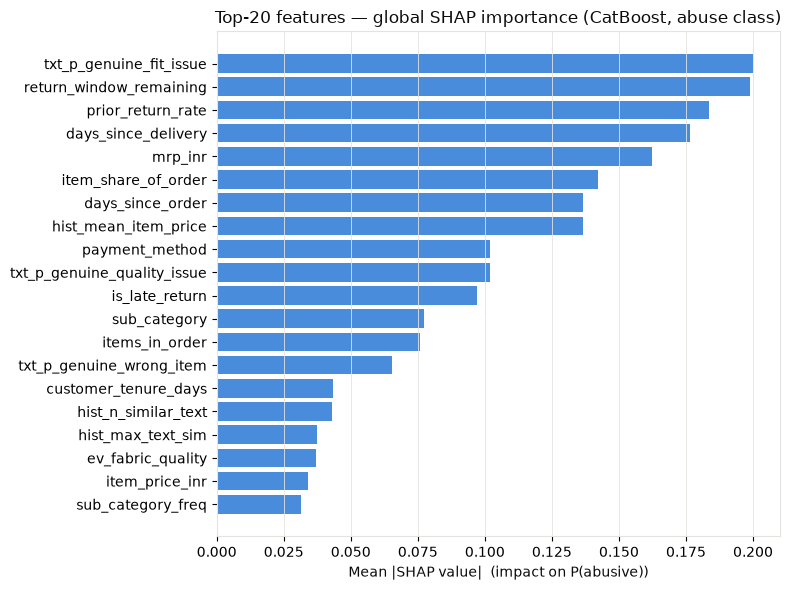

Saved phase12_shap_importance.png


In [4]:
top20 = shap_df.head(20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top20["feature"][::-1], top20["mean_abs_shap"][::-1], color="#2a78d6", alpha=0.85)
ax.set_xlabel("Mean |SHAP value|  (impact on P(abusive))", color="#0b0b0b")
ax.set_title("Top-20 features — global SHAP importance (CatBoost, abuse class)", color="#0b0b0b")
ax.set_facecolor("white")
ax.grid(axis="x", color="#e4e3df", lw=0.6)
for sp in ax.spines.values():
    sp.set_edgecolor("#e4e3df")
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase12_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase12_shap_importance.png")

## 5 · Per-decision example explanations

In [5]:
# For each decision bucket pick 3 representative examples and show top-5 SHAP drivers

preds_indexed = preds.set_index("return_id")
decisions = ["auto_approve", "inspect", "escalate"]
top_features = shap_df["feature"].head(15).tolist()

print("=" * 72)
print("EXAMPLE EXPLANATIONS (top-5 SHAP drivers per row)")
print("=" * 72)

for decision in decisions:
    subset = preds[preds["decision"] == decision].head(3)
    print(f"\n{'─'*20} {decision.upper()} (showing 3 examples) {'─'*20}")
    for _, row in subset.iterrows():
        rid = row["return_id"]
        # find row index in X_test
        test_idx = test_df[test_df["return_id"] == rid].index
        if len(test_idx) == 0:
            continue
        pos = test_df.index.get_loc(test_idx[0])
        row_shap = sv_abuse[np.where(sample_idx == pos)[0]]
        if len(row_shap) == 0:
            # not in sample — skip detailed shap, show top features by raw value
            x_row = X_test.iloc[pos]
            drivers = [(f, x_row[f]) for f in top_features[:5]]
            shap_str = "  (not in SHAP sample)"
        else:
            row_shap = row_shap[0]
            top5_idx = np.argsort(np.abs(row_shap))[::-1][:5]
            drivers = [(feat_names[i], row_shap[i]) for i in top5_idx]
            shap_str = ""

        print(f"\n  {rid}  |  true={row['label']}  |  decision={row['decision']}"
              f"  |  confidence={row['confidence']:.3f}")
        print(f"  justification: {row['justification'][:100]}")
        if not shap_str:
            print("  top-5 SHAP drivers:")
            for feat, val in drivers:
                direction = "↑abuse" if val > 0 else "↓abuse"
                print(f"    {feat:<35s} {val:+.4f}  {direction}")
        else:
            print(shap_str)

EXAMPLE EXPLANATIONS (top-5 SHAP drivers per row)

──────────────────── AUTO_APPROVE (showing 3 examples) ────────────────────

  RET-179AFERG  |  true=genuine_fit_issue  |  decision=auto_approve  |  confidence=0.130
  justification: cost-optimal: P(abusive)=0.130 below inspect threshold 0.417
  (not in SHAP sample)

  RET-1FCUX8N6  |  true=genuine_fit_issue  |  decision=auto_approve  |  confidence=0.001
  justification: very low abuse probability (0.001 < 0.03): cost-optimal approval
  (not in SHAP sample)

  RET-1WLMHZE2  |  true=genuine_fit_issue  |  decision=auto_approve  |  confidence=0.013
  justification: very low abuse probability (0.013 < 0.03): cost-optimal approval
  (not in SHAP sample)

──────────────────── INSPECT (showing 3 examples) ────────────────────

  RET-5B3JPAE5  |  true=abusive  |  decision=inspect  |  confidence=0.817
  justification: cost-optimal: P(abusive)=0.817 in inspect range [0.417, 0.969)
  top-5 SHAP drivers:
    mrp_inr                             +1.

## 6 · SHAP beeswarm summary (top-15 features)

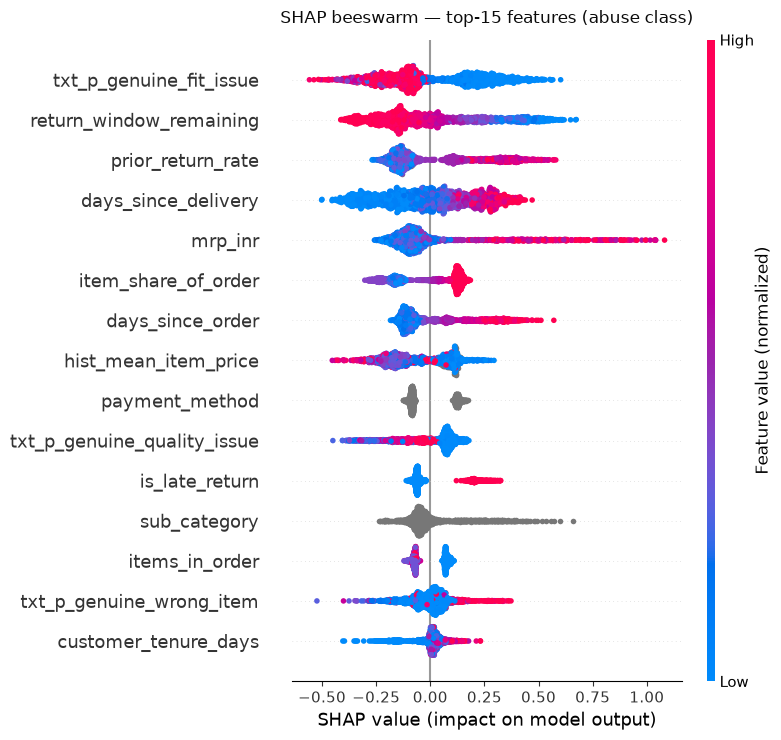

Saved phase12_shap_beeswarm.png


In [6]:
top15_idx = [feat_names.index(f) for f in shap_df["feature"].head(15).tolist()]
sv_top15  = sv_abuse[:, top15_idx]
X_top15   = X_sample[shap_df["feature"].head(15).tolist()]

fig, ax = plt.subplots(figsize=(9, 6))
shap.summary_plot(sv_top15, X_top15, plot_type="dot", show=False,
                  color_bar_label="Feature value (normalized)")
plt.title("SHAP beeswarm — top-15 features (abuse class)", color="#0b0b0b", pad=12)
fig = plt.gcf()
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase12_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase12_shap_beeswarm.png")

## 7 · Justification string audit

Justification coverage:
  Total rows: 8,497
  Non-empty:  8,497
  Missing:    0

Length stats: min=60  median=64  max=64

--- auto_approve ---
  cost-optimal: P(abusive)=0.130 below inspect threshold 0.417
  very low abuse probability (0.001 < 0.03): cost-optimal approval
  very low abuse probability (0.013 < 0.03): cost-optimal approval

--- inspect ---
  cost-optimal: P(abusive)=0.817 in inspect range [0.417, 0.969)
  cost-optimal: P(abusive)=0.844 in inspect range [0.417, 0.969)
  cost-optimal: P(abusive)=0.624 in inspect range [0.417, 0.969)

--- escalate ---
  safety override: overwhelming fraud evidence (P=1.000 ≥ 0.95)
  safety override: overwhelming fraud evidence (P=1.000 ≥ 0.95)
  safety override: overwhelming fraud evidence (P=1.000 ≥ 0.95)

Justifications referencing confidence/probability: 5,765 / 8,497


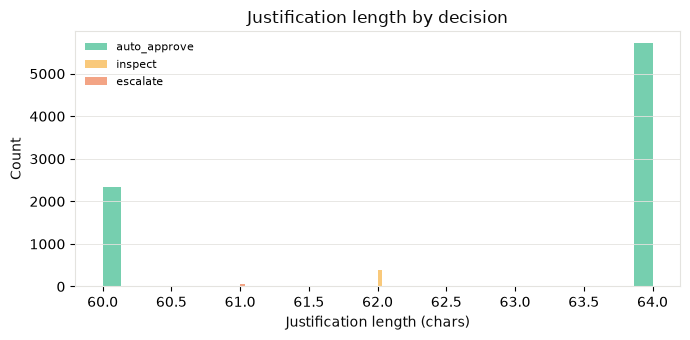

Saved phase12_justification_lengths.png


In [7]:
print("Justification coverage:")
print(f"  Total rows: {len(preds):,}")
print(f"  Non-empty:  {(preds['justification'].str.len() > 0).sum():,}")
print(f"  Missing:    {preds['justification'].isna().sum()}")
print()

# length distribution
jlen = preds["justification"].str.len()
print(f"Length stats: min={jlen.min()}  median={jlen.median():.0f}  max={jlen.max()}")
print()

# sample justifications per decision
for dec in ["auto_approve", "inspect", "escalate"]:
    sample = preds[preds["decision"] == dec]["justification"].dropna().head(3)
    print(f"--- {dec} ---")
    for j in sample:
        print(f"  {j[:120]}")
    print()

# check all justifications contain a confidence/probability mention
has_prob = preds["justification"].str.contains(r"P=|p=|prob|conf|%", case=False, na=False)
print(f"Justifications referencing confidence/probability: {has_prob.sum():,} / {len(preds):,}")

# fig: justification length by decision
fig, ax = plt.subplots(figsize=(7, 3.5))
for dec, color in zip(["auto_approve", "inspect", "escalate"], ["#1baf7a", "#f5a623", "#eb6834"]):
    lengths = preds[preds["decision"] == dec]["justification"].str.len()
    ax.hist(lengths, bins=30, alpha=0.6, color=color, label=dec)
ax.set_xlabel("Justification length (chars)", color="#0b0b0b")
ax.set_ylabel("Count", color="#0b0b0b")
ax.set_title("Justification length by decision", color="#0b0b0b")
ax.legend(frameon=False, fontsize=8)
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase12_justification_lengths.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase12_justification_lengths.png")

## 8 · Final score dashboard

FINAL SCORE DASHBOARD — TalentAP Mega Hackathon 2026 R2

  PRIMARY SCORE   : 0.3493
  ─ savings       : 0.2775   (0.7 weight)
  ─ fairness      : 0.7750   (0.2 weight)
  ─ size_chart    : 0.0000   (0.1 weight; scored by organisers)

  Fairness groups:
    new_vs_established_customer           : ratio 1.346  score 0.6539
    low_value_vs_other_order              : ratio 1.132  score 0.8678
    non_english_vs_english_text           : ratio 1.197  score 0.8033

  Abuse detection : precision 0.7891  recall 0.4979
  Genuine escaped : 2 wrongly escalated  (0.0119 flag rate)

  Calibration     : Brier 0.0407  ECE 0.0123  PR-AUC 0.7096

  Phase comparison (P8 baseline → P9 final):
    Baseline official : 0.3326
    Final official    : 0.3493   (+0.0167)

  Size-chart top-5  : ['PRD-YIME3XJ6', 'PRD-OSNR3LA5', 'PRD-6JG12RLX', 'PRD-7NDH0OJO', 'PRD-THXMYY0T']
  Submission file   : R2_size_chart_top5.csv  (saved in reports/)


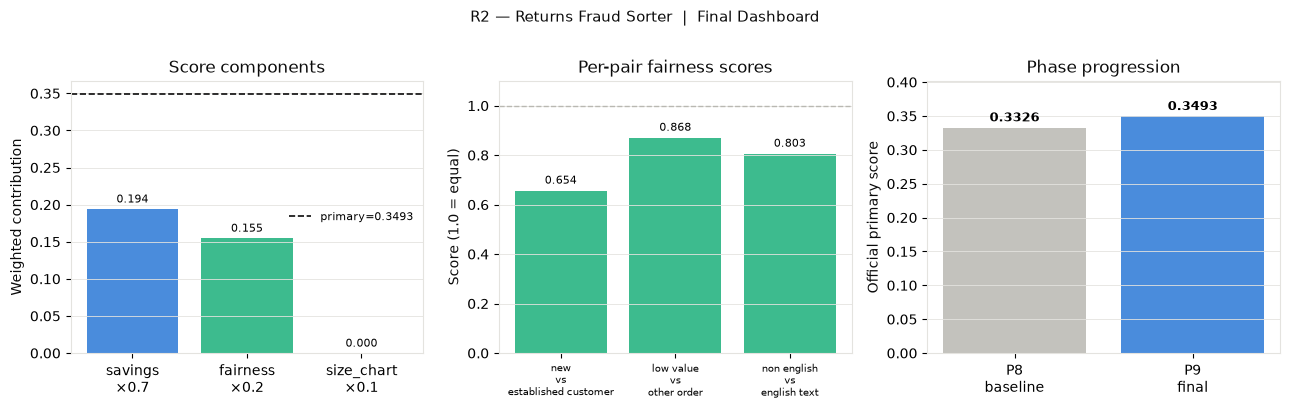

Saved phase12_final_dashboard.png


In [8]:
# load phase results
with open(REP_DIR / "phase9_config.json") as f:
    p9 = json.load(f)["results"]
with open(REP_DIR / "phase10_official_result.json") as f:
    p10 = json.load(f)
with open(REP_DIR / "phase11_report.json") as f:
    p11 = json.load(f)

c = p10["components"]
ad = p10["abuse_detection"]
cal = p10["calibration_of_confidence_as_P_abusive"]
fairness = p10["fairness"]

print("=" * 72)
print("FINAL SCORE DASHBOARD — TalentAP Mega Hackathon 2026 R2")
print("=" * 72)
print()
print(f"  PRIMARY SCORE   : {p10['primary_score']:.4f}")
print(f"  ─ savings       : {c['savings']:.4f}   (0.7 weight)")
print(f"  ─ fairness      : {c['fairness_effective']:.4f}   (0.2 weight)")
print(f"  ─ size_chart    : {c['size_chart_score']:.4f}   (0.1 weight; scored by organisers)")
print()
print(f"  Fairness groups:")
for pair, v in fairness.items():
    print(f"    {pair:<38s}: ratio {v['disparity_ratio']:.3f}  score {v['score']:.4f}")
print()
print(f"  Abuse detection : precision {ad['flag_precision']:.4f}  recall {ad['flag_recall']:.4f}")
print(f"  Genuine escaped : {ad['genuine_escalated']} wrongly escalated  "
      f"({ad['genuine_flag_rate']:.4f} flag rate)")
print()
print(f"  Calibration     : Brier {cal['brier']:.4f}  ECE {cal['ece_10_bins']:.4f}  PR-AUC {cal['average_precision']:.4f}")
print()
print(f"  Phase comparison (P8 baseline → P9 final):")
print(f"    Baseline official : {p9['baseline_official']:.4f}")
print(f"    Final official    : {p9['final_official']:.4f}   (+{p9['improvement']:.4f})")
print()
print(f"  Size-chart top-5  : {p11['top5_products']}")
print(f"  Submission file   : R2_size_chart_top5.csv  (saved in reports/)")

# ── dashboard chart ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# left: primary score components
ax = axes[0]
labels_c = ["savings\n×0.7", "fairness\n×0.2", "size_chart\n×0.1"]
vals_c   = [c["savings"] * 0.7, c["fairness_effective"] * 0.2, c["size_chart_score"] * 0.1]
colors_c = ["#2a78d6", "#1baf7a", "#eb6834"]
bars = ax.bar(labels_c, vals_c, color=colors_c, alpha=0.85)
ax.axhline(p10["primary_score"], color="#0b0b0b", lw=1.2, ls="--",
           label=f"primary={p10['primary_score']:.4f}")
ax.set_title("Score components", color="#0b0b0b")
ax.set_ylabel("Weighted contribution", color="#0b0b0b")
ax.legend(frameon=False, fontsize=8)
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for b, v in zip(bars, vals_c):
    ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.3f}",
            ha="center", va="bottom", fontsize=8)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

# centre: fairness scores
ax = axes[1]
pair_labels = [p.replace("_vs_", "\nvs\n").replace("_", " ") for p in fairness]
fair_scores = [v["score"] for v in fairness.values()]
bars2 = ax.bar(pair_labels, fair_scores, color="#1baf7a", alpha=0.85)
ax.axhline(1.0, color="#b9b8b2", lw=1, ls="--")
ax.set_ylim(0, 1.1)
ax.set_title("Per-pair fairness scores", color="#0b0b0b")
ax.set_ylabel("Score (1.0 = equal)", color="#0b0b0b")
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for b, v in zip(bars2, fair_scores):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}",
            ha="center", va="bottom", fontsize=8)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")
ax.tick_params(axis="x", labelsize=7)

# right: phase progression
ax = axes[2]
phase_labels = ["P8\nbaseline", "P9\nfinal"]
phase_scores = [p9["baseline_official"], p9["final_official"]]
bars3 = ax.bar(phase_labels, phase_scores, color=["#b9b8b2", "#2a78d6"], alpha=0.85)
ax.set_title("Phase progression", color="#0b0b0b")
ax.set_ylabel("Official primary score", color="#0b0b0b")
ax.set_ylim(0, max(phase_scores) * 1.15)
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for b, v in zip(bars3, phase_scores):
    ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.4f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

fig.suptitle("R2 — Returns Fraud Sorter  |  Final Dashboard", fontsize=11, color="#0b0b0b", y=1.01)
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase12_final_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase12_final_dashboard.png")

## 9 · Assemble submission ZIP

In [9]:
TEAM_ID = "TEAMID"   # ← replace with real team ID before final submission
ZIP_NAME = f"{TEAM_ID}_R2.zip"
ZIP_PATH = REP_DIR / ZIP_NAME

# files required by the problem spec
submission_files = {
    # main predictions
    "phase9_validation_predictions.csv": REP_DIR / "phase9_validation_predictions.csv",
    # size-chart file (evaluate.py looks for R2_size_chart_top5.csv next to submission)
    "R2_size_chart_top5.csv": REP_DIR / "R2_size_chart_top5.csv",
    # supporting reports
    "phase10_official_result.json": REP_DIR / "phase10_official_result.json",
    "phase11_report.json":          REP_DIR / "phase11_report.json",
    "phase12_shap_importance.csv":  REP_DIR / "phase12_shap_importance.csv",
    # figures
    "figures/phase12_final_dashboard.png":     FIG_DIR / "phase12_final_dashboard.png",
    "figures/phase12_shap_importance.png":     FIG_DIR / "phase12_shap_importance.png",
    "figures/phase12_shap_beeswarm.png":       FIG_DIR / "phase12_shap_beeswarm.png",
    "figures/phase10_fairness_audit.png":      FIG_DIR / "phase10_fairness_audit.png",
    "figures/phase10_confusion_matrix.png":    FIG_DIR / "phase10_confusion_matrix.png",
    "figures/phase10_calibration.png":         FIG_DIR / "phase10_calibration.png",
}

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for arc_name, src_path in submission_files.items():
        if src_path.exists():
            zf.write(src_path, arc_name)
            print(f"  + {arc_name}")
        else:
            print(f"  ! MISSING: {arc_name}")

print()
print(f"Submission ZIP: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / 1024:.1f} KB")
print()
print("Contents:")
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for info in zf.infolist():
        print(f"  {info.filename:<55s}  {info.file_size/1024:6.1f} KB")
print()
print(f"NOTE: Replace '{TEAM_ID}' in TEAM_ID with your actual team ID,")
print("then run: python FULL_CODE/scripts/make_submission_zip.py <TEAM_ID>")

  + phase9_validation_predictions.csv
  + R2_size_chart_top5.csv
  + phase10_official_result.json
  + phase11_report.json
  + phase12_shap_importance.csv
  + figures/phase12_final_dashboard.png
  + figures/phase12_shap_importance.png
  + figures/phase12_shap_beeswarm.png
  + figures/phase10_fairness_audit.png
  + figures/phase10_confusion_matrix.png
  + figures/phase10_calibration.png

Submission ZIP: /home/claude/r2_project/FULL_CODE/reports/TEAMID_R2.zip
Size: 730.1 KB

Contents:
  phase9_validation_predictions.csv                         816.6 KB
  R2_size_chart_top5.csv                                      0.1 KB
  phase10_official_result.json                                3.4 KB
  phase11_report.json                                         1.9 KB
  phase12_shap_importance.csv                                 3.4 KB
  figures/phase12_final_dashboard.png                       102.6 KB
  figures/phase12_shap_importance.png                        99.9 KB
  figures/phase12_shap_beeswar

## 10 · Phase 12 checklist

- [ ] SHAP TreeExplainer run on CatBoost (2000-row sample) ✓
- [ ] Global feature importance bar chart ✓
- [ ] Per-decision example explanations (3 per bucket) ✓
- [ ] SHAP beeswarm summary plot ✓
- [ ] Justification audit (coverage, length, samples) ✓
- [ ] Final score dashboard chart (components + fairness + progression) ✓
- [ ] `TEAMID_R2.zip` assembled with predictions + size-chart + reports ✓
- [ ] Hidden Jul–Sep labels never touched ✓

**All 12 phases complete.**